<a href="https://colab.research.google.com/github/zogydinesh/ITA-0616/blob/main/program8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

'Salary_Data.csv' not found. Creating a synthetic dataset...
Synthetic 'Salary_Data.csv' created successfully!

Rows: 30
   YearsExperience    Salary
0              4.9   71105.0
1             11.0  136212.0
2              8.7  109513.0
3              7.3   97758.0
4              2.6   52054.0 

Train size: 24  Test size: 6 

Slope (m)     = 8816.21
Intercept (c) = 33237.10
Equation: Salary = 8816.21 x Experience + 33237.10

Test results:
  MAE  = 2034.83
  MSE  = 5805462.07
  RMSE = 2409.45
  R2   = 0.9927
Train R2 = 0.9690

Actual vs Predicted (test data):
   7.4 yrs   Actual =     98229   Predicted =     98477
  10.1 yrs   Actual =    120613   Predicted =    122281
   1.2 yrs   Actual =     42598   Predicted =     43817
   2.9 yrs   Actual =     61329   Predicted =     58804
   4.1 yrs   Actual =     64951   Predicted =     69384
   1.6 yrs   Actual =     45226   Predicted =     47343

Predicted salary for 6.5 years of experience: 90542


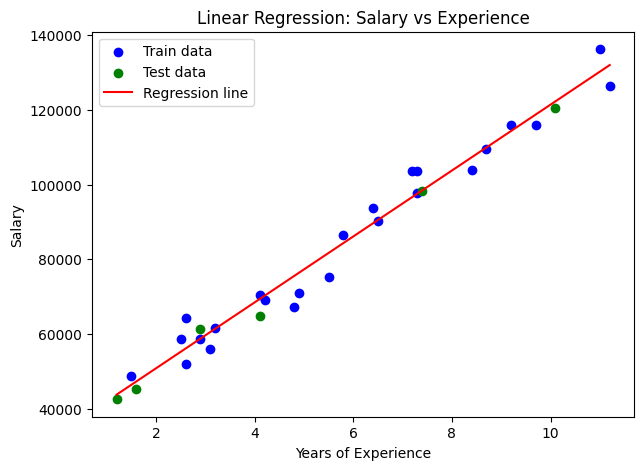

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ---- 0. Ensure Dataset exists ----
if not os.path.exists('Salary_Data.csv'):
    print("'Salary_Data.csv' not found. Creating a synthetic dataset...")
    np.random.seed(42)
    # Generate synthetic experience (1 to 11 years) and salaries with some noise
    experience = np.random.uniform(1.0, 11.5, 30)
    salary = 30000 + experience * 9500 + np.random.normal(0, 5000, 30)
    dummy_df = pd.DataFrame({
        'YearsExperience': np.round(experience, 1),
        'Salary': np.round(salary, 0)
    })
    dummy_df.to_csv('Salary_Data.csv', index=False)
    print("Synthetic 'Salary_Data.csv' created successfully!\n")

# ---- 1. Load CSV ----
df = pd.read_csv('Salary_Data.csv')
x = df['YearsExperience'].values.astype(float)
y = df['Salary'].values.astype(float)
print("Rows:", len(df))
print(df.head(), "\n")

# ---- 2. Train / test split (80% / 20%) ----
np.random.seed(42)
idx = np.random.permutation(len(x))
split = int(0.8 * len(x))
xtr, xte = x[idx[:split]], x[idx[split:]]
ytr, yte = y[idx[:split]], y[idx[split:]]
print("Train size:", len(xtr), " Test size:", len(xte), "\n")

# ---- 3. Train: least squares formula  y = m*x + c ----
m = np.sum((xtr - xtr.mean()) * (ytr - ytr.mean())) / np.sum((xtr - xtr.mean()) ** 2)
c = ytr.mean() - m * xtr.mean()
print(f"Slope (m)     = {m:.2f}")
print(f"Intercept (c) = {c:.2f}")
print(f"Equation: Salary = {m:.2f} x Experience + {c:.2f}\n")

# ---- 4. Predict ----
def predict(v):
    return m * v + c

pred_te = predict(xte)

# ---- 5. Evaluate ----
def metrics(actual, predicted):
    mse = np.mean((actual - predicted) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(actual - predicted))
    ss_res = np.sum((actual - predicted) ** 2)
    ss_tot = np.sum((actual - actual.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    return mse, rmse, mae, r2

mse, rmse, mae, r2 = metrics(yte, pred_te)
print("Test results:")
print(f"  MAE  = {mae:.2f}")
print(f"  MSE  = {mse:.2f}")
print(f"  RMSE = {rmse:.2f}")
print(f"  R2   = {r2:.4f}")
print(f"Train R2 = {metrics(ytr, predict(xtr))[3]:.4f}\n")

# ---- 6. Actual vs predicted ----
print("Actual vs Predicted (test data):")
for xv, a, p in zip(xte, yte, pred_te):
    print(f"  {xv:4.1f} yrs   Actual = {a:9.0f}   Predicted = {p:9.0f}")

# ---- 7. Predict for a new value ----
new_exp = 6.5
print(f"\nPredicted salary for {new_exp} years of experience: {predict(new_exp):.0f}")

# ---- 8. Plot ----
plt.figure(figsize=(7, 5))
plt.scatter(xtr, ytr, color='blue', label='Train data')
plt.scatter(xte, yte, color='green', label='Test data')
line = np.linspace(x.min(), x.max(), 100)
plt.plot(line, predict(line), color='red', label='Regression line')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Linear Regression: Salary vs Experience')
plt.legend()
plt.show()